# Comparative Implementation of Six Regression Algorithms

**Dataset:** Scikit-learn Diabetes dataset (442 real records).  
**Prediction problem:** Predict one-year disease progression using **BMI only**.  
**Feature:** `bmi_x1000` (standardized BMI multiplied by 1000 for readability); **target:** `disease_progression`.  
**Fair comparison:** The same 80:20 train/test split (`random_state=42`) is reused for every algorithm. Feature scaling is fitted **only on training data** when needed.

> The six-row or three-row examples in the handwritten work are conceptual demonstrations, not rows used to train the Python models. The CSV supplied with this notebook contains the real 442-row dataset.

## 1. Install and import libraries
Run cells from top to bottom in Google Colab or Jupyter. The file `diabetes_regression_dataset.csv` can be uploaded beside the notebook. If it is not available, the notebook loads **the same** original data directly from scikit-learn.

In [1]:
# In Colab, run this only if xgboost is not installed:
# %pip install -q xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42
np.random.seed(SEED)


## 2. Load and inspect dataset

In [2]:
csv_path = Path("diabetes_regression_dataset.csv")
if csv_path.exists():
    df = pd.read_csv(csv_path)
    print("Loaded supplied CSV:", csv_path)
else:
    diabetes = load_diabetes()
    df = pd.DataFrame({
        "patient_id": np.arange(1, len(diabetes.target) + 1),
        "bmi_x1000": np.round(diabetes.data[:, 2] * 1000, 5),
        "disease_progression": diabetes.target.astype(int),
    })
    print("CSV not found; loaded the identical source dataset from scikit-learn.")
    df.to_csv(csv_path, index=False)

assert df.shape == (442, 3), f"Unexpected dataset shape: {df.shape}"
assert not df.isna().any().any(), "Missing values detected"
display(df.head(8))
print("Rows:", len(df))
print("Feature: bmi_x1000 | Target: disease_progression")


Loaded supplied CSV: diabetes_regression_dataset.csv


,patient_id,bmi_x1000,disease_progression
0,1,61.69621,151
1,2,-51.47406,75
2,3,44.45121,141
3,4,-11.59501,206
4,5,-36.38469,135
5,6,-40.69594,97
6,7,-47.16281,138
7,8,-1.89471,63


Rows: 442
Feature: bmi_x1000 | Target: disease_progression


## 3. Preprocessing and same 80:20 split for every model
There are no missing values. Patient ID is an identifier, not an input feature. Models sensitive to feature scale (KNN and Neural Network) use `StandardScaler` inside a pipeline to avoid leakage.

In [3]:
X = df[["bmi_x1000"]]            # SAME input for every model
y = df["disease_progression"]   # SAME target for every model

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print(f"Training records: {len(X_train)} | Testing records: {len(X_test)}")
assert len(X_train) == 353 and len(X_test) == 89


Training records: 353 | Testing records: 89


## 4. Train six regression algorithms
Algorithms: Linear Regression, Decision Tree, Random Forest, Neural Network (MLP), XGBoost and KNN. Hyperparameters are fixed for a reproducible introductory comparison; this is **not** an exhaustive hyperparameter search.

In [4]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=4, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=5, random_state=SEED, n_jobs=-1),
    "Neural Network": make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(16, 8), activation="relu", solver="lbfgs",
                     max_iter=2000, random_state=SEED)
    ),
    "XGBoost": XGBRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                            subsample=1.0, colsample_bytree=1.0,
                            objective="reg:squarederror", random_state=SEED, n_jobs=2),
    "KNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=9)),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print("Trained:", name)


Trained: Linear Regression
Trained: Decision Tree


Trained: Random Forest
Trained: Neural Network


Trained: XGBoost
Trained: KNN


## 5. Evaluate MAE, MSE, RMSE and R²
**Smaller** MAE, MSE and RMSE are better. **Larger** R² is better. All metrics are computed on the **same 89 test records**.

In [5]:
results = []
for name, y_pred in predictions.items():
    mse = mean_squared_error(y_test, y_pred)
    results.append({
        "Algorithm": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, y_pred),
    })

metrics_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(metrics_df.round(3))
metrics_df.to_csv("six_regression_metrics.csv", index=False)
print("Saved: six_regression_metrics.csv")


,Algorithm,MAE,MSE,RMSE,R2
0,XGBoost,51.030,3965.538,62.973,0.252
1,Random Forest,50.921,4038.044,63.546,0.238
2,Linear Regression,52.260,4061.826,63.732,0.233
3,KNN,50.645,4070.467,63.800,0.232
4,Neural Network,52.134,4218.145,64.947,0.204
5,Decision Tree,53.779,4391.205,66.266,0.171


Saved: six_regression_metrics.csv


## 6. Visualize actual versus predicted values for all six models
The dashed diagonal represents perfect prediction. Points closer to the diagonal indicate better predictions.

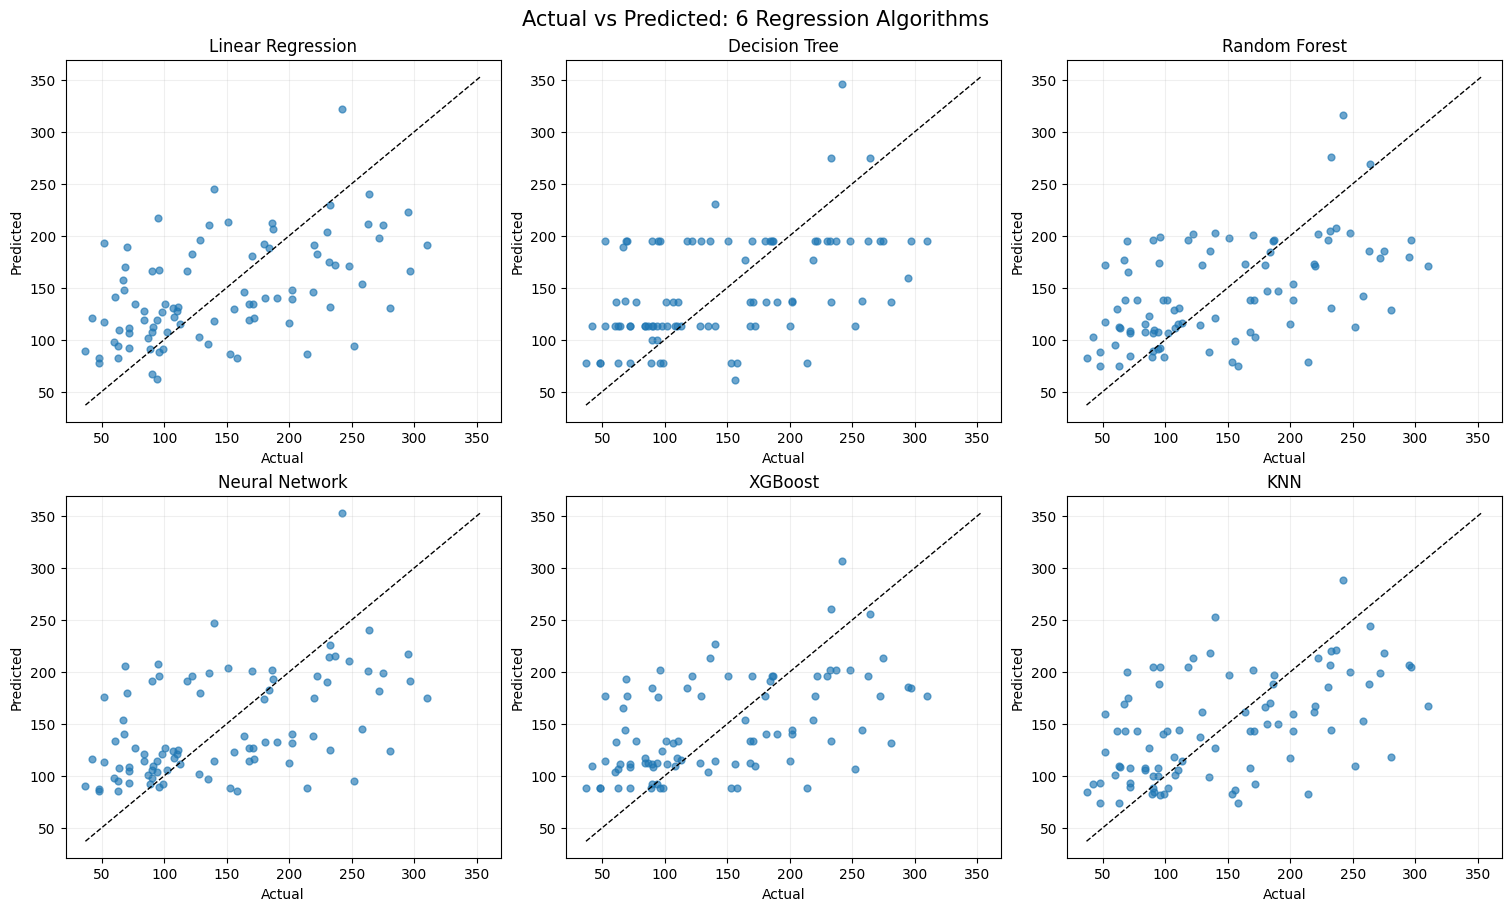

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
y_actual = y_test.to_numpy()
min_val = min(y_actual.min(), *(p.min() for p in predictions.values()))
max_val = max(y_actual.max(), *(p.max() for p in predictions.values()))
for ax, (name, y_pred) in zip(axes.flat, predictions.items()):
    ax.scatter(y_actual, y_pred, alpha=0.65, s=24)
    ax.plot([min_val, max_val], [min_val, max_val], "k--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.grid(alpha=0.2)
fig.suptitle("Actual vs Predicted: 6 Regression Algorithms", fontsize=15)
Path("assets").mkdir(exist_ok=True)
plt.savefig("assets/actual_vs_predicted_six_models.png", dpi=180, bbox_inches="tight")
plt.show()


## 7. Compare RMSE across algorithms

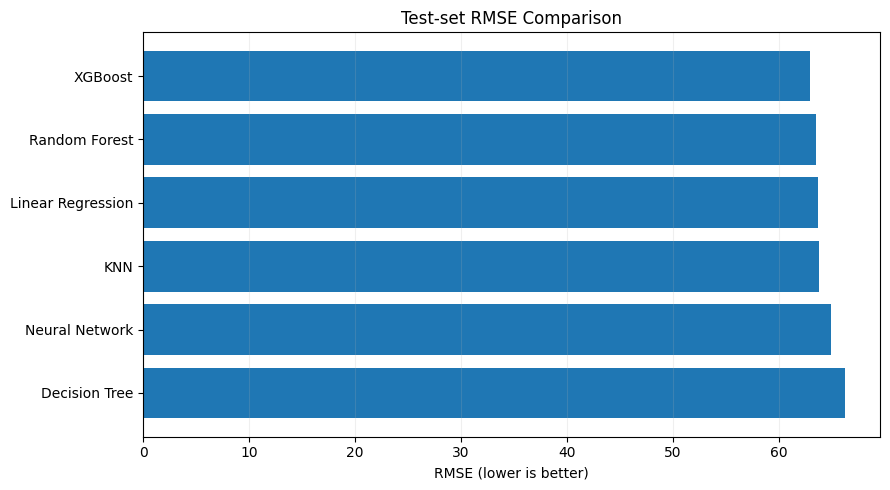

In [7]:
plot_df = metrics_df.sort_values("RMSE", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df["Algorithm"], plot_df["RMSE"])
ax.invert_yaxis()
ax.set_xlabel("RMSE (lower is better)")
ax.set_title("Test-set RMSE Comparison")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.savefig("assets/rmse_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


## 8. Strengths and limitations

| Model | Strength | Limitation |
|---|---|---|
| Linear Regression | Fast and interpretable | Limited to a straight-line relationship |
| Decision Tree | Simple rules; handles nonlinear trends | Can overfit |
| Random Forest | Reduces variance by averaging trees | More computation and harder to interpret |
| Neural Network | Flexible nonlinear learning | Sensitive to tuning and training settings |
| XGBoost | Strong boosted-tree method | More parameters to tune |
| KNN | Intuitive similarity-based prediction | Sensitive to scale and neighborhood size |

## 9. Automatically identify the best model and conclude
Best here is defined by **lowest test RMSE**, with R² as supporting evidence. Small differences may change with another split or parameter choices.

In [8]:
best = metrics_df.iloc[0]
print(f"Best by RMSE: {best['Algorithm']}")
print(f"MAE={best['MAE']:.2f}; MSE={best['MSE']:.2f}; "
      f"RMSE={best['RMSE']:.2f}; R²={best['R2']:.3f}")
print("Conclusion: On this fixed split and setup,", best['Algorithm'],
      "has the lowest RMSE. The results apply to BMI-only prediction; "
      "adding other clinical features could improve performance.")


Best by RMSE: XGBoost
MAE=51.03; MSE=3965.54; RMSE=62.97; R²=0.252
Conclusion: On this fixed split and setup, XGBoost has the lowest RMSE. The results apply to BMI-only prediction; adding other clinical features could improve performance.


## 10. Submission checklist

- Dataset CSV: `diabetes_regression_dataset.csv` (442 rows; 3 columns)
- Handwritten working: six concise explanations and illustrative calculations (separate paper)
- Python notebook: six trained regression methods using identical X, y and test split
- Metrics: MAE, MSE, RMSE and R² (generated CSV)
- Plots: six actual-versus-predicted scatterplots and RMSE comparison
- Strengths, limitations and evidence-based conclusion

**Source:** `sklearn.datasets.load_diabetes` — the standardized BMI feature is multiplied by 1000 purely for readability.